# Figure 2 plotting and assembly

This notebook reads only the validated outputs produced by the Figure 2
analysis notebook. It renders publication-ready panels and assembles the final
multi-panel figure using the visual style established for Figure 1.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from PIL import Image as PILImage, ImageChops, ImageOps

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
)
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "figure_2_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_2_clean"
PANEL_DIR = FIGURE_DIR / "panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)

panel_ab = pd.read_csv(DATA_DIR / "panels_a_b_purity_models.csv")
panel_c = pd.read_csv(DATA_DIR / "panel_c_locked_matched_null.csv")
panel_d = pd.read_csv(DATA_DIR / "panel_d_global_pc_robustness.csv")

BLUE = "#0072B2"
ORANGE = "#D55E00"
TEAL = "#009E73"
PURPLE = "#7A5195"
DARK = "#27313D"
MID = "#657286"
BAND = "#F3F6F8"
GRID = "#DCE3E8"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


def p_text(value):
    if value < 0.001:
        return f"{value:.1e}"
    return f"{value:.3f}"


def save_panel(fig, stem):
    paths = {
        "png": PANEL_DIR / f"{stem}.png",
        "svg": PANEL_DIR / f"{stem}.svg",
        "pdf": PANEL_DIR / f"{stem}.pdf",
    }
    fig.savefig(paths["png"], dpi=400, facecolor="white")
    fig.savefig(paths["svg"], facecolor="white")
    fig.savefig(paths["pdf"], facecolor="white")
    return paths


def panel_letter(fig, letter):
    fig.text(0.025, 0.96, letter, fontsize=34, fontweight="bold",
             color=DARK, ha="left", va="top")


def effect_panel(data, letter, stem, subtitle):
    data = data.set_index("endpoint").loc[["Grade", "Stage"]].reset_index()
    y = np.array([1, 0])
    colors = [BLUE, ORANGE]
    fig, ax = plt.subplots(figsize=(10.4, 5.3))
    fig.patch.set_facecolor(WHITE)
    for index in range(len(data)):
        if index % 2 == 0:
            ax.axhspan(y[index] - 0.34, y[index] + 0.34,
                       color=BAND, zorder=0)
        row = data.iloc[index]
        color = colors[index]
        ax.errorbar(
            row["beta"], y[index],
            xerr=[[row["beta"] - row["ci_low"]],
                  [row["ci_high"] - row["beta"]]],
            fmt="o", color=color, ecolor=color, markersize=13,
            elinewidth=4, capsize=8, capthick=2.5,
            markeredgecolor=WHITE, markeredgewidth=2.2, zorder=3,
        )
        ax.text(
            0.965, y[index],
            rf"$\beta$ = {row['beta']:.2f}" + "\n" +
            rf"$P$ = {p_text(row['p_value'])}",
            transform=ax.get_yaxis_transform(),
            ha="right", va="center", color=color,
            fontsize=13.5, fontweight="bold",
            bbox={"boxstyle": "round,pad=0.40,rounding_size=0.16",
                  "facecolor": (1, 1, 1, 0.82),
                  "edgecolor": color, "linewidth": 1.3},
        )
    labels = [
        f"{row.endpoint}   $n$={int(row.n)}"
        for row in data.itertuples(index=False)
    ]
    ax.set_yticks(y, labels, fontsize=15, color=DARK)
    ax.axvline(0, color="#AEB8C2", linestyle="--", linewidth=1.5)
    # Reserve a dedicated right-hand annotation column so even the widest
    # confidence interval in Panel B cannot touch the statistics box.
    ax.set_xlim(-0.03, 0.68)
    ax.set_ylim(-0.55, 1.55)
    ax.set_xlabel(r"Adjusted effect per SD Mitoxy ($\beta$)",
                  fontsize=16, labelpad=15)
    ax.text(0.0, 1.04, subtitle, transform=ax.transAxes,
            fontsize=13, color=MID, ha="left")
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.tick_params(axis="y", length=0, pad=14)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#8B96A3")
    panel_letter(fig, letter)
    fig.subplots_adjust(left=0.25, right=0.95, top=0.88, bottom=0.20)
    paths = save_panel(fig, stem)
    plt.show()
    return paths


## Panels A and B


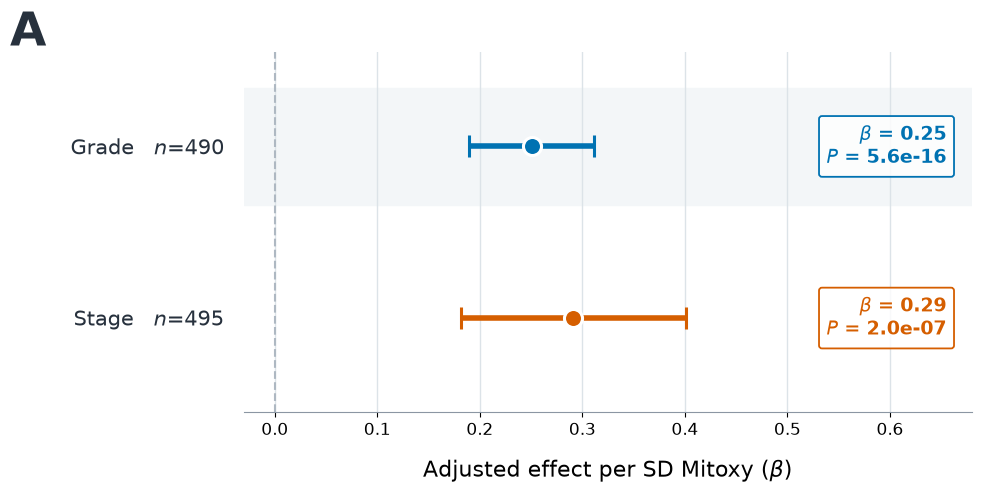

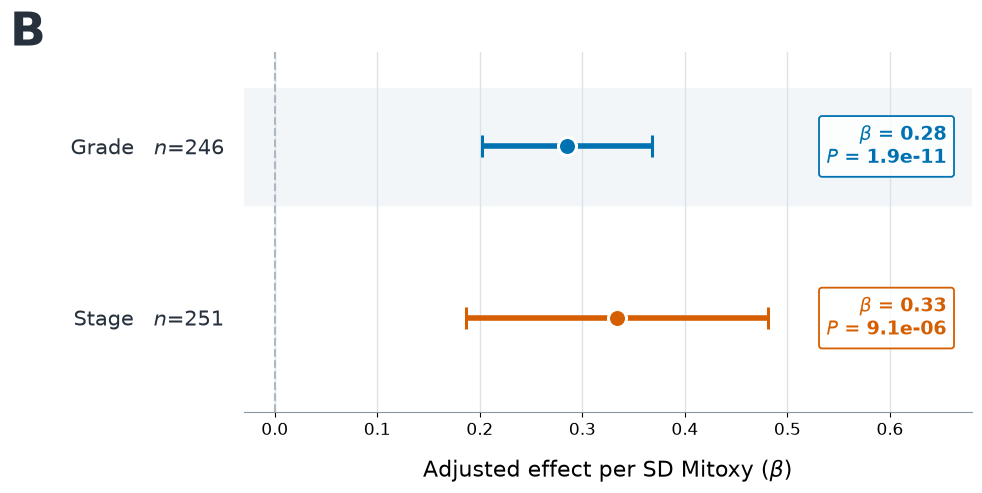

In [2]:
panel_a_paths = effect_panel(
    panel_ab.loc[panel_ab["analysis"].eq("Purity-adjusted full cohort")],
    "A", "figure_2a_purity_adjusted",
    "",
)
panel_b_paths = effect_panel(
    panel_ab.loc[panel_ab["analysis"].eq("High-purity sensitivity")],
    "B", "figure_2b_high_purity",
    "",
)


## Panel C — locked matched-null specificity


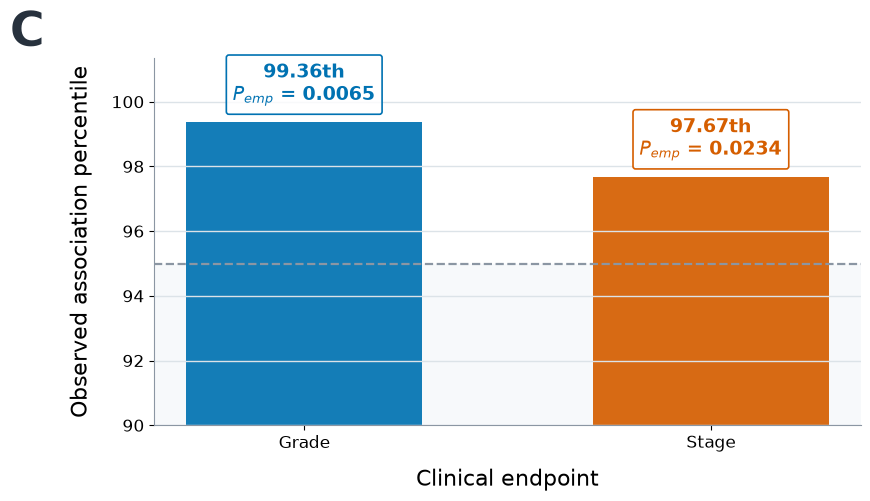

In [3]:
data = panel_c.set_index("endpoint").loc[["Grade", "Stage"]].reset_index()
colors = [BLUE, ORANGE]
fig, ax = plt.subplots(figsize=(9.3, 5.4))
fig.patch.set_facecolor(WHITE)
# Draw from the displayed 90th-percentile baseline. This avoids creating
# oversized clipped rectangles below the visible axis while preserving the
# intended percentile comparison.
bars = ax.bar(data["endpoint"], data["percentile"] - 90, bottom=90,
              color=colors, width=0.58, alpha=0.92)
ax.axhspan(90, 95, color="#F7F9FB", zorder=0)
ax.axhline(95, color="#8B96A3", linestyle="--", linewidth=1.6)
for bar, row, color in zip(bars, data.itertuples(index=False), colors):
    ax.text(
        bar.get_x() + bar.get_width() / 2, row.percentile + 0.45,
        f"{row.percentile:.2f}th\n" + rf"$P_{{emp}}$ = {row.empirical_p:.4f}",
        ha="center", va="bottom", color=color,
        fontsize=13.5, fontweight="bold",
        bbox={"boxstyle": "round,pad=0.34,rounding_size=0.14",
              "facecolor": (1, 1, 1, 0.82),
              "edgecolor": color, "linewidth": 1.2},
    )
ax.set_ylim(90, 101.35)
ax.set_ylabel("Observed association percentile", fontsize=16, labelpad=14)
ax.set_xlabel("Clinical endpoint", fontsize=16, labelpad=12)
ax.grid(axis="y", color=GRID, linewidth=1)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#8B96A3")
panel_letter(fig, "C")
fig.subplots_adjust(left=0.18, right=0.94, top=0.87, bottom=0.19)
panel_c_paths = save_panel(fig, "figure_2c_locked_matched_null")
plt.show()


## Panel D — global-expression PC robustness


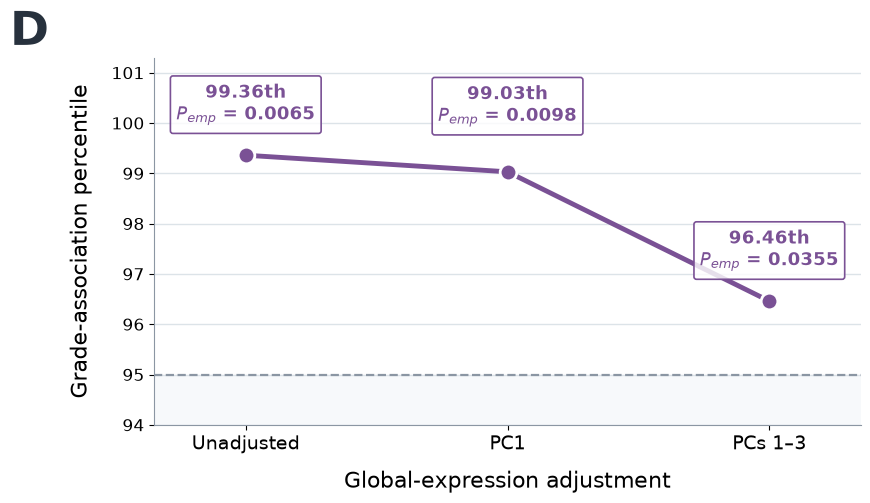

In [4]:
order = ["Raw", "PC1", "PC1-3"]
data = panel_d.set_index("adjustment").loc[order].reset_index()
x = np.arange(len(data))
fig, ax = plt.subplots(figsize=(9.3, 5.4))
fig.patch.set_facecolor(WHITE)
ax.plot(x, data["percentile"], color=PURPLE, linewidth=3.5,
        marker="o", markersize=12, markeredgecolor=WHITE,
        markeredgewidth=2, zorder=3)
ax.axhspan(94, 95, color="#F7F9FB", zorder=0)
ax.axhline(95, color="#8B96A3", linestyle="--", linewidth=1.6)
label_offsets = [0.55, 0.85, 0.55]
for position, row, offset in zip(
    x, data.itertuples(index=False), label_offsets
):
    ax.text(
        position, row.percentile + offset,
        f"{row.percentile:.2f}th\n" + rf"$P_{{emp}}$ = {row.empirical_p:.4f}",
        ha="center", va="bottom", color=PURPLE,
        fontsize=13.2, fontweight="bold",
        bbox={"boxstyle": "round,pad=0.32,rounding_size=0.14",
              "facecolor": (1, 1, 1, 0.82),
              "edgecolor": PURPLE, "linewidth": 1.2},
    )
ax.set_xticks(x, ["Unadjusted", "PC1", "PCs 1–3"], fontsize=14)
ax.set_ylim(94, 101.30)
ax.set_xlim(-0.35, 2.35)
ax.set_ylabel("Grade-association percentile", fontsize=16, labelpad=14)
ax.set_xlabel("Global-expression adjustment", fontsize=16, labelpad=12)
ax.grid(axis="y", color=GRID, linewidth=1)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#8B96A3")
panel_letter(fig, "D")
fig.subplots_adjust(left=0.18, right=0.94, top=0.87, bottom=0.19)
panel_d_paths = save_panel(fig, "figure_2d_global_pc_robustness")
plt.show()


## Assemble Figure 2


Saved:
/scratch/ar58064/mitoxy/figures/figure_2_clean/Figure_2_complete.png
/scratch/ar58064/mitoxy/figures/figure_2_clean/Figure_2_complete.tiff


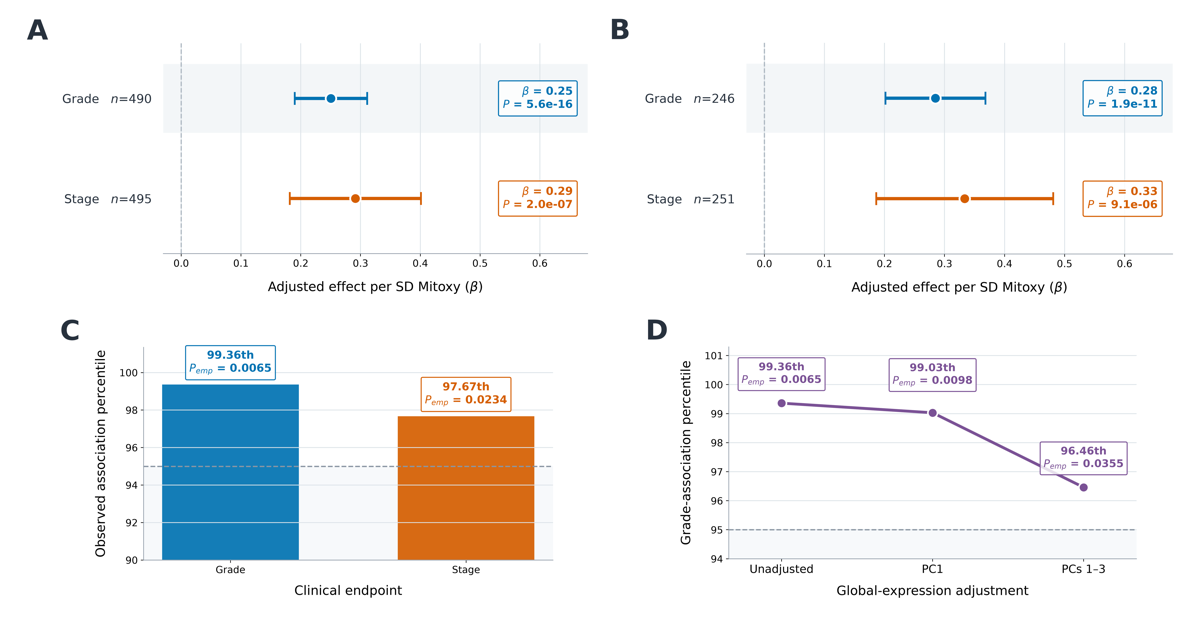

In [5]:
panel_paths = {
    "A": panel_a_paths["png"],
    "B": panel_b_paths["png"],
    "C": panel_c_paths["png"],
    "D": panel_d_paths["png"],
}


def trim_image(image, border=30):
    image = image.convert("RGB")
    background = PILImage.new("RGB", image.size, "white")
    difference = ImageChops.difference(image, background)
    box = difference.getbbox()
    if box is None:
        return image
    left, upper, right, lower = box
    return image.crop((
        max(0, left - border), max(0, upper - border),
        min(image.width, right + border), min(image.height, lower + border),
    ))


def place_contained(canvas, image_path, box):
    left, top, right, bottom = box
    image = trim_image(PILImage.open(image_path))
    image.thumbnail((right - left, bottom - top), PILImage.Resampling.LANCZOS)
    x = left + (right - left - image.width) // 2
    y = top + (bottom - top - image.height) // 2
    canvas.paste(image, (x, y))


canvas = PILImage.new("RGB", (6400, 3300), "white")
boxes = {
    "A": (120, 70, 3160, 1600),
    "B": (3240, 70, 6280, 1600),
    "C": (120, 1680, 3160, 3210),
    "D": (3240, 1680, 6280, 3210),
}
for letter, path in panel_paths.items():
    place_contained(canvas, path, boxes[letter])

final_png = FIGURE_DIR / "Figure_2_complete.png"
final_tiff = FIGURE_DIR / "Figure_2_complete.tiff"
canvas.save(final_png, dpi=(400, 400))
canvas.save(final_tiff, dpi=(400, 400), compression="tiff_lzw")

print("Saved:")
print(final_png)
print(final_tiff)
display(canvas.resize((1200, 619)))
